In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import plotting_functions

In [2]:
# Parameters
q = 4
L = 20
# Load data as 1D arrays
h0_re = np.loadtxt("data_Figs/Fig_Selection_Coeff_Toy_Model/h0_q_4_L_20_mu_h_0.0_sigma_h_0.05.txt")
h1_re = np.loadtxt("data_Figs/Fig_Selection_Coeff_Toy_Model/infered_h_1000_replicates_q_4_L_20_mu_h_0.0_sigma_h_0.05.txt")
# Reshape assuming Julia column-major order
h0_mat = h0_re.reshape((L, q)).T
h1_mat = h1_re.reshape((L, q)).T

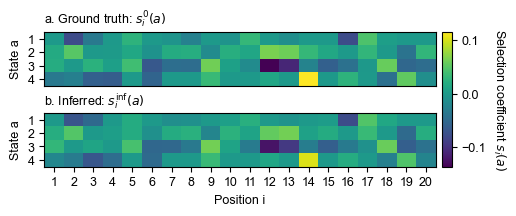

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec


cell_size = 30  # pixels
fig_width = L * cell_size / 100
fig_height = q * cell_size * 2.5 / 100  # Taller for room

# Labels
lab_1 = r"$s^0_i(a)$"
lab_2 = r"$s^{\mathrm{inf}}_i(a)$"
cbar_label = r"Selection coefficient $s_i(a)$"

# Color limits
vmin = min(h0_mat.min(), h1_mat.min())
vmax = max(h0_mat.max(), h1_mat.max())

# Create figure and gridspec
#fig, ax = plt.subplots(figsize=(1.5*plotwidth, 0.5*plotwidth))

#fig = plt.figure(figsize=(fig_width + 1, fig_height))
fig = plt.figure(figsize=plotting_functions.get_figsize("horizontal"))

gs = gridspec.GridSpec(2, 2, width_ratios=[20, 0.5], height_ratios=[1, 1], hspace=0.5,wspace=0.03)

# Plot h0
ax1 = fig.add_subplot(gs[0, 0])
im1 = ax1.imshow(h0_mat, aspect='auto', cmap='viridis', vmin=vmin, vmax=vmax)
ax1.set_title(f"a. Ground truth: {lab_1}", loc='left')
ax1.set_ylabel("State a")
ax1.set_xticks([])
ax1.set_yticks(np.arange(q))
ax1.set_yticklabels([str(a + 1) for a in range(q)])

# Plot h1
ax2 = fig.add_subplot(gs[1, 0])
im2 = ax2.imshow(h1_mat, aspect='auto', cmap='viridis', vmin=vmin, vmax=vmax)
ax2.set_title(f"b. Inferred: {lab_2}", loc='left')
ax2.set_xlabel("Position i")
ax2.set_ylabel("State a")
ax2.set_xticks(np.arange(L))
ax2.set_xticklabels(np.arange(1, L + 1))
ax2.set_yticks(np.arange(q))
ax2.set_yticklabels([str(a + 1) for a in range(q)])

# Shared colorbar
cax = fig.add_subplot(gs[:, 1])  # vertical span for both rows
cbar = fig.colorbar(im2, cax=cax)
cbar.set_label(cbar_label, rotation=270, labelpad=15)

# Show or save
#plt.savefig("selection_coeff_inference_toy_model_shared_cbar.pdf", bbox_inches='tight')
plt.show()